# Princeton summer tomato trial

In [1]:
from pathlib import Path
import os
from IPython.display import display, Image

ROOT = Path.cwd()
if ROOT.name == "06_princeton":
    ROOT = ROOT.parent.parent
if not (ROOT / "batches").is_dir():
    raise FileNotFoundError("Open this notebook from the project folder.")
BATCH_DIR = ROOT / "batches/06_princeton"
os.chdir(BATCH_DIR)
%matplotlib inline

## Workbook

Yield weights in pounds per plot. A dot indicates a missing value.

In [2]:
from __future__ import annotations

import html

import re

from pathlib import Path

import matplotlib.pyplot as plt

import numpy as np

import pandas as pd

from openpyxl import load_workbook

workbook = ROOT / "data/raw/Princeton Tomato Trial 2026.xlsx"

figures = Path("figures")

figures.mkdir(exist_ok=True)

HARVESTS = [
    ("Harvest 1", "2026-07-14", 61),
    ("Harvest 2", "2026-07-22", 69),
    ("Harvest 3", "2026-07-29", 76),
    ("Harvest 4", "2026-08-07", 85),
    ("Harvest 5", "2026-08-17", 95),
    ("Harvest 6", "2026-08-24", 102),
    ("Harvest 7", "2026-09-01", 110),
    ("Harvest 8", "2026-09-08", 117),
    ("Harvest 9", "2026-09-16", 125),
    ("Harvest 10", "2026-09-25", 134),
]

FIELD_DAY = {
    "UKYT-25-014": "Tasted at field day",
    "UKYT-25-017": "Field-day favorite. Intense flavor, compared with Cherokee Purple.",
    "UKYT-26-006": "Tasted at field day",
    "UKYT-26-028": "Tasted at field day",
    "NC 255G": "Least favored at field day. Noted as bland.",
    "NC 262G": "Tasted at field day",
    "Mountain Magic": "Tasted at field day",
    "NC 25218G": "Tasted at field day",
    "NC 25311G": "Tasted at field day",
}

def clean_genotype(name: str) -> str:
    text = " ".join(str(name).split())
    text = text.replace("UKYT ", "UKYT-").replace("UKYT-", "UKYT-")
    return text

def to_number(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return np.nan
    if isinstance(value, str):
        text = value.strip()
        if text in {"", ".", "-", "—"}:
            return np.nan
        try:
            return float(text)
        except ValueError:
            return np.nan
    return float(value)

## Harvest blocks

In [3]:
def read_block(sheet: str) -> pd.DataFrame:
    raw = pd.read_excel(workbook, sheet_name=sheet, header=None)
    # Row 2 (index 1) holds harvest labels. Data start at Excel row 3 (index 2).
    rows = []
    for i in range(2, len(raw)):
        entry = raw.iat[i, 0]
        if pd.isna(entry) or str(entry).startswith("Grape") or str(entry).startswith("%") or str(entry).startswith("Slicer"):
            continue
        entry = clean_genotype(entry)
        if entry in {"Grape Average", "Grape Total", "Slicer & Cocktail Average", "Slicer & Cocktail Total"}:
            continue
        record = {"Entry": entry}
        for h, (label, _date, _dap) in enumerate(HARVESTS):
            record[f"{label} fruit"] = to_number(raw.iat[i, 1 + h])
            record[f"{label} lb"] = to_number(raw.iat[i, 16 + h])
        rows.append(record)
    return pd.DataFrame(rows)

marketable = read_block("Marketable Yield").rename(
    columns={c: f"mkt_{c}" if c != "Entry" else c for c in read_block("Marketable Yield").columns}
)

cull_raw = read_block("Cull Yield")

cull = cull_raw.rename(columns={c: f"cull_{c}" if c != "Entry" else c for c in cull_raw.columns})

lines = pd.read_excel(workbook, sheet_name="Tomato Lines", header=1)

lines["Entry"] = lines["Entries/Lines"].map(clean_genotype)

lines = lines.rename(
    columns={
        "Note": "Trial role",
        "Plant number in field": "Plants",
        "Growth habit": "Habit",
        "Other notes": "Entry notes",
    }
)

## Entry and layout details

In [4]:
lines = lines[["Entry", "Trial role", "Plants", "Habit", "Type", "Color", "Entry notes"]]

taste = pd.read_excel(workbook, sheet_name="Cull & Tasting Notes")

taste = taste.rename(
    columns={
        "Entry/Line": "Entry",
        "Fruit type": "Fruit shape",
        "Reasons for Culls": "Cull reasons",
        "Taste Rating": "Staff taste rating",
        "Tasting Notes (7/29-30), 1=poor, 2=fair, 3=good, 4=very good, 5=excellent": "Staff tasting notes",
    }
)

taste["Entry"] = taste["Entry"].map(lambda x: clean_genotype(x) if pd.notna(x) else x)

taste = taste[["Entry", "Fruit shape", "Cull reasons", "Staff taste rating", "Staff tasting notes"]]

def match_key(name):
    """Ignore spaces. Keep a trailing G on NC names; South Farm records both forms."""
    if pd.isna(name):
        return None
    text = re.sub(r"\s+", "", str(name).strip()).upper()
    uk = re.match(r"(?:UKYT|UKY)(\d{2})-?(\d{1,3})$", text)
    if uk:
        return f"UKYT-{uk.group(1)}-{int(uk.group(2)):03d}"
    nc = re.match(r"NC(\d+)(G)?$", text)
    if nc:
        return f"NC{nc.group(1)}{nc.group(2) or ''}"
    return re.sub(r"[^A-Z0-9]", "", text)

def join_key_for_site(princeton_key, site_keys):
    """Use the exact name. If the site only has the form without G, use that."""
    if princeton_key in site_keys:
        return princeton_key
    if princeton_key and princeton_key.endswith("G") and princeton_key[:-1] in site_keys:
        return princeton_key[:-1]
    return princeton_key

layout_rows = []

layout_ws = load_workbook(workbook, data_only=False)["Layout"]

for excel_row in range(3, 20):
    for col, field_row in ((1, 1), (4, 2), (7, 3), (10, 4), (13, 5)):
        name = layout_ws.cell(excel_row, col).value
        code = layout_ws.cell(excel_row, col + 1).value
        if name:
            layout_rows.append(
                {
                    "Entry": clean_genotype(name),
                    "Field row": field_row,
                    "Layout code": code,
                }
            )

layout = pd.DataFrame(layout_rows)

stand_notes = {
    "UKYT-26-001": "Management note: 3 plants after poor germination; one undersized and one with foliar distortion.",
    "NC 25207G": "Management note: 3 plants after poor germination.",
    "NC 25240G": "Management note: 3 plants after poor germination.",
    "UKYT-25-016": "Management note: one plant broke at the first stringing; one undersized plant.",
    "UKYT-26-017": "Management note: one plant broke at the first stringing.",
    "UKYT-26-028": "Management note: one plant broke at the first stringing.",
    "UKYT-26-025": "Management note: one undersized plant; foliar distortion questioned.",
    "UKYT-26-033": "Management note: one undersized plant.",
    "NC 25230G": "Management note: one undersized plant.",
    "NC 25217G": "Management note: one undersized plant; foliar distortion questioned.",
    "NC 23926G": "Management note: one undersized plant; foliar distortion questioned.",
    "NC 25241G": "Management note: one undersized plant (written NC2541G); foliar distortion questioned.",
}

## Season totals and coverage

Grape fruit counts cover harvests 1–3. Yield weights cover all recorded harvests.

In [5]:
summary = marketable.merge(cull, on="Entry", how="outer")

summary = summary.merge(lines, on="Entry", how="left")

summary = summary.merge(taste, on="Entry", how="left")

summary = summary.merge(layout, on="Entry", how="left")

summary["Stand note"] = summary["Entry"].map(stand_notes)

fruit_mkt_cols = [f"mkt_Harvest {i} fruit" for i in range(1, 11)]

fruit_cull_cols = [f"cull_Harvest {i} fruit" for i in range(1, 11)]

lb_mkt_cols = [f"mkt_Harvest {i} lb" for i in range(1, 11)]

lb_cull_cols = [f"cull_Harvest {i} lb" for i in range(1, 11)]

summary["Marketable fruit"] = summary[fruit_mkt_cols].sum(axis=1, min_count=1)

summary["Cull fruit"] = summary[fruit_cull_cols].sum(axis=1, min_count=1)

summary["Marketable lb"] = summary[lb_mkt_cols].sum(axis=1, min_count=1)

summary["Cull lb"] = summary[lb_cull_cols].sum(axis=1, min_count=1)

summary["Total fruit"] = summary[["Marketable fruit", "Cull fruit"]].sum(axis=1, min_count=1)

summary["Total lb"] = summary[["Marketable lb", "Cull lb"]].sum(axis=1, min_count=1)

summary["Marketable fruit %"] = summary["Marketable fruit"] / summary["Total fruit"] * 100

summary["Marketable yield %"] = summary["Marketable lb"] / summary["Total lb"] * 100

summary["Harvests with fruit count"] = summary[fruit_mkt_cols].notna().sum(axis=1)

summary["Harvests with marketable weight"] = summary[lb_mkt_cols].notna().sum(axis=1)

summary["Mean marketable fruit / harvest"] = summary[fruit_mkt_cols].mean(axis=1, skipna=True)

summary["Mean marketable lb / harvest"] = summary[lb_mkt_cols].mean(axis=1, skipna=True)

summary["Mean marketable fruit oz"] = np.where(
    summary["Marketable fruit"] > 0,
    summary["Marketable lb"] / summary["Marketable fruit"] * 16,
    np.nan,
)

paired_oz_num = []

paired_fruit = []

for i in range(1, 11):
    fruit = summary[f"mkt_Harvest {i} fruit"]
    lb = summary[f"mkt_Harvest {i} lb"]
    both = fruit.notna() & lb.notna() & (fruit > 0)
    paired_oz_num.append(np.where(both, lb * 16, 0.0))
    paired_fruit.append(np.where(both, fruit, 0.0))

paired_fruit_sum = np.sum(paired_fruit, axis=0)

summary["Counted marketable lb"] = np.sum(
    [
        np.where(
            summary[f"mkt_Harvest {i} fruit"].notna()
            & summary[f"mkt_Harvest {i} lb"].notna()
            & (summary[f"mkt_Harvest {i} fruit"] > 0),
            summary[f"mkt_Harvest {i} lb"],
            0.0,
        )
        for i in range(1, 11)
    ],
    axis=0,
)

summary["Counted marketable fruit"] = paired_fruit_sum

summary["Mean oz on counted harvests"] = np.where(
    summary["Counted marketable fruit"] > 0,
    summary["Counted marketable lb"] / summary["Counted marketable fruit"] * 16,
    np.nan,
)

summary["Uncounted marketable lb"] = summary["Marketable lb"] - summary["Counted marketable lb"]

summary["Marketable lb / plant"] = summary["Marketable lb"] / summary["Plants"]

summary["Class"] = np.where(
    summary["Type"].eq("grape tomato"),
    "Grape",
    "Slicer and cocktail",
)

summary["Field-day note"] = summary["Entry"].map(FIELD_DAY)

## Harvest and entry tables

In [6]:
long_rows = []

for _, row in summary.iterrows():
    for i, (label, date, dap) in enumerate(HARVESTS, start=1):
        long_rows.append(
            {
                "Entry": row["Entry"],
                "Class": row["Class"],
                "Type": row["Type"],
                "Habit": row["Habit"],
                "Plants": row["Plants"],
                "Harvest": label,
                "Date": date,
                "Days after planting": dap,
                "Marketable fruit": row[f"mkt_Harvest {i} fruit"],
                "Marketable lb": row[f"mkt_Harvest {i} lb"],
                "Cull fruit": row[f"cull_Harvest {i} fruit"],
                "Cull lb": row[f"cull_Harvest {i} lb"],
            }
        )

long_df = pd.DataFrame(long_rows)

long_df.to_csv("princeton_harvest_master.csv", index=False)

keep = [
    "Entry",
    "Class",
    "Type",
    "Habit",
    "Color",
    "Trial role",
    "Plants",
    "Marketable fruit",
    "Cull fruit",
    "Total fruit",
    "Marketable fruit %",
    "Mean marketable fruit / harvest",
    "Harvests with fruit count",
    "Marketable lb",
    "Cull lb",
    "Total lb",
    "Marketable yield %",
    "Mean marketable lb / harvest",
    "Harvests with marketable weight",
    "Marketable lb / plant",
    "Mean oz on counted harvests",
    "Uncounted marketable lb",
    "Cull reasons",
    "Staff taste rating",
    "Staff tasting notes",
    "Entry notes",
    "Field-day note",
    "Field row",
    "Layout code",
    "Stand note",
]

summary[keep].sort_values(["Class", "Marketable lb"], ascending=[True, False]).to_csv(
    "princeton_genotype_summary.csv", index=False
)

def top_table(frame: pd.DataFrame, n: int = 15) -> pd.DataFrame:
    return frame.sort_values("Marketable lb", ascending=False).head(n)

grapes = summary[summary["Class"].eq("Grape")].copy()

slicers = summary[summary["Class"].eq("Slicer and cocktail")].copy()

summary[summary["Entry"].isin(FIELD_DAY)].sort_values(
    "Marketable lb", ascending=False
)[keep].to_csv("princeton_field_day_entries.csv", index=False)

top_table(grapes)[keep].to_csv("top15_princeton_grape_marketable_lb.csv", index=False)

top_table(slicers)[keep].to_csv("top15_princeton_slicer_marketable_lb.csv", index=False)

## Cross-site comparison

The other sites use grams. Trial totals are not pooled.

In [7]:
summary["match_key"] = summary["Entry"].map(match_key)

def load_site(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path)
    frame["match_key"] = frame["Genotypes"].map(match_key)
    return frame

ht = load_site(ROOT / "batches/02_high_tunnel/genotype_summary.csv")

sf = load_site(ROOT / "batches/05_south_farm/south_farm_genotype_summary.csv")

rc = load_site(ROOT / "batches/04_robinson/robinson_genotype_summary.csv")

brix = load_site(ROOT / "batches/03_brix/genotype_location_brix.csv")

ht["HT rank"] = ht["total_marketable_weight"].rank(ascending=False, method="min")

sf["SF marketable rank"] = sf["total_marketable_weight_g"].rank(ascending=False, method="min")

sf["SF total rank"] = sf["total_weight_g"].rank(ascending=False, method="min")

rc["RC rank"] = rc["total_marketable_weight"].rank(ascending=False, method="min")

rc["RC total rank"] = rc["total_weight"].rank(ascending=False, method="min")

n_ht, n_sf, n_rc = ht["match_key"].nunique(), sf["match_key"].nunique(), rc["match_key"].nunique()

brix_wide = brix.pivot_table(
    index="match_key",
    columns="Location",
    values=["mean_brix", "n"],
    aggfunc="sum",
)

brix_wide.columns = [f"{stat} {loc}" for stat, loc in brix_wide.columns]

def attach_site(frame: pd.DataFrame, site: pd.DataFrame, rename_map: dict) -> pd.DataFrame:
    keys = set(site["match_key"])
    left = frame.copy()
    left["site_key"] = left["match_key"].map(lambda key: join_key_for_site(key, keys))
    right = site[["match_key", *rename_map]].rename(
        columns={"match_key": "site_key", **rename_map}
    )
    return left.merge(right, on="site_key", how="left").drop(columns=["site_key"])

cross = summary[
    ["Entry", "match_key", "Class", "Marketable lb", "Marketable yield %", "Staff taste rating"]
].copy()

cross = attach_site(
    cross,
    ht,
    {
        "total_marketable_weight": "HT marketable g",
        "marketable_percentage": "HT marketable %",
        "n_harvests_with_weight": "HT harvests",
        "HT rank": "HT rank",
    },
)

cross = attach_site(
    cross,
    sf,
    {
        "total_weight_g": "SF total g",
        "total_marketable_weight_g": "SF marketable g",
        "marketable_percentage": "SF marketable %",
        "n_harvests_with_weight": "SF harvests",
        "SF marketable rank": "SF marketable rank",
        "SF total rank": "SF total rank",
        "mean_brix_south_farm": "SF Brix on yield file",
    },
)

cross = attach_site(
    cross,
    rc,
    {
        "total_marketable_weight": "RC marketable g",
        "marketable_percentage": "RC marketable %",
        "RC rank": "RC rank",
        "RC total rank": "RC total rank",
        "total_weight": "RC total g",
    },
)

brix_keys = set(brix_wide.index)

cross["site_key"] = cross["match_key"].map(lambda key: join_key_for_site(key, brix_keys))

cross = cross.merge(brix_wide, left_on="site_key", right_index=True, how="left").drop(
    columns=["site_key"]
)

cross.drop(columns=["match_key"]).sort_values(
    ["Class", "Marketable lb"], ascending=[True, False]
).to_csv("princeton_cross_site.csv", index=False)

In [8]:
n_ht_join = int(cross["HT rank"].notna().sum())

n_sf_join = int(cross["SF total g"].notna().sum())

n_rc_join = int(cross["RC rank"].notna().sum())

n_brix_join = int(cross.filter(like="mean_brix ").notna().any(axis=1).sum())

n_any = int(
    (cross["HT rank"].notna() | cross["SF total g"].notna() | cross["RC rank"].notna()).sum()
)

only_here = cross.loc[
    cross["HT rank"].isna() & cross["SF total g"].isna() & cross["RC rank"].isna(),
    "Entry",
].tolist()

def rank_corr(left, right):
    pair = pd.DataFrame({"left": left, "right": right}).dropna()
    if len(pair) < 3:
        return float("nan"), 0
    return float(pair["left"].rank().corr(pair["right"].rank())), int(len(pair))

def value_corr(left, right):
    pair = pd.DataFrame({"left": left, "right": right}).dropna()
    if len(pair) < 3:
        return float("nan"), 0
    return float(pair["left"].corr(pair["right"])), int(len(pair))

pr_order = cross["Marketable lb"].rank(ascending=False, method="min")

rho_ht, ncorr_ht = rank_corr(pr_order, cross["HT rank"])

rho_sf, ncorr_sf = rank_corr(pr_order, cross["SF marketable rank"])

rho_rc, ncorr_rc = rank_corr(pr_order, cross["RC rank"])

pct_ht, npct_ht = value_corr(cross["Marketable yield %"], cross["HT marketable %"])

pct_sf, npct_sf = value_corr(cross["Marketable yield %"], cross["SF marketable %"])

pct_rc, npct_rc = value_corr(cross["Marketable yield %"], cross["RC marketable %"])

if len(cross) != len(summary):
    raise SystemExit(f"cross-site join duplicated rows: {len(cross)} vs {len(summary)}")

bacterial_lines = summary.loc[
    summary["Cull reasons"].astype(str).str.contains("bacterial", case=False, na=False),
    "Entry",
].tolist()

def rank_label(rank, n):
    if pd.isna(rank):
        return "—"
    return f"{int(rank)} / {n}"

def brix_label(row, location):
    value = row.get(f"mean_brix {location}")
    assays = row.get(f"n {location}")
    if pd.isna(value):
        return "—"
    assays_txt = "" if pd.isna(assays) else f" (n={int(assays)})"
    return f"{value:.1f}{assays_txt}"

field_cross = cross[cross["Entry"].isin(FIELD_DAY)].sort_values(
    "Marketable lb", ascending=False
).copy()

field_cross["HT"] = field_cross["HT rank"].map(lambda r: rank_label(r, n_ht))

field_cross["SF mkt"] = field_cross["SF marketable rank"].map(lambda r: rank_label(r, n_sf))

field_cross["SF total"] = field_cross["SF total rank"].map(lambda r: rank_label(r, n_sf))

field_cross["RC"] = field_cross["RC rank"].map(lambda r: rank_label(r, n_rc))

field_cross["RC total"] = field_cross["RC total rank"].map(lambda r: rank_label(r, n_rc))

field_cross["Brix HT"] = field_cross.apply(lambda r: brix_label(r, "High tunnel"), axis=1)

field_cross["Brix SF"] = field_cross.apply(lambda r: brix_label(r, "South Farm"), axis=1)

field_cross["Brix RC"] = field_cross.apply(lambda r: brix_label(r, "Robinson"), axis=1)

## Yield and harvest plots

In [9]:
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": "#1a1a1a",
    }
)

MKT_COLOR = "#0033A0"

CULL_COLOR = "#B0B0B0"

harvest_labels = [f"H{i}\n{d[5:7].lstrip('0')}/{d[8:].lstrip('0')}" for i, (_, d, _) in enumerate(HARVESTS, start=1)]

def top_table(frame: pd.DataFrame, col: str = "Marketable lb", n: int = 15) -> pd.DataFrame:
    out = frame.sort_values(col, ascending=False).head(n).copy()
    out.insert(0, "Rank", range(1, len(out) + 1))
    return out

def plot_top15_bars(frame, col, path, title, xlabel, digits=1):
    plot = frame.sort_values(col, ascending=True)
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    ax.barh(plot["Entry"], plot[col], color=MKT_COLOR)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for y, v in enumerate(plot[col]):
        ax.text(v + plot[col].max() * 0.01, y, f"{v:.{digits}f}", va="center", fontsize=8, color="#4a4a4a")
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

grape_top = top_table(grapes)

slicer_top = top_table(slicers)

plot_top15_bars(
    grape_top,
    "Marketable lb",
    figures / "princeton_fig1_grape_top15_marketable.png",
    "Top 15 grape entries by total marketable yield (Princeton)",
    "Total marketable yield (lb / plot)",
)

plot_top15_bars(
    slicer_top,
    "Marketable lb",
    figures / "princeton_fig2_slicer_top15_marketable.png",
    "Top 15 slicer and cocktail entries by total marketable yield (Princeton)",
    "Total marketable yield (lb / plot)",
)

by_harvest = long_df.groupby("Harvest", sort=False)[["Marketable lb", "Cull lb"]].sum()

fig, ax = plt.subplots(figsize=(9, 5.5))

x = np.arange(len(HARVESTS))

ax.bar(x - 0.2, by_harvest["Marketable lb"], width=0.38, color=MKT_COLOR, label="Marketable")

ax.bar(x + 0.2, by_harvest["Cull lb"], width=0.38, color=CULL_COLOR, label="Cull")

ax.set_xticks(x)

ax.set_xticklabels(harvest_labels, fontsize=8)

ax.set_ylabel("Weight, all plots (lb)")

ax.set_title("Marketable and cull weight at each harvest (all 83 entries)")

ax.legend(fontsize=8, frameon=False)

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(figures / "princeton_fig3_weight_by_harvest.png", dpi=150)

plt.close(fig)

In [10]:
def plot_cumulative(frame, path, title, n=6):
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for entry in frame["Entry"].head(n):
        vals = long_df.loc[long_df["Entry"].eq(entry), "Marketable lb"].fillna(0).cumsum()
        ax.plot(x, vals.values, marker="o", linewidth=1.8, label=entry)
    ax.set_xticks(x)
    ax.set_xticklabels(harvest_labels, fontsize=8)
    ax.set_ylabel("Cumulative marketable yield (lb / plot)")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="upper left", frameon=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylim(bottom=0)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)

plot_cumulative(
    grape_top,
    figures / "princeton_fig4_grape_cumulative.png",
    "Cumulative marketable yield, top 6 grape entries",
)

plot_cumulative(
    slicer_top,
    figures / "princeton_fig5_slicer_cumulative.png",
    "Cumulative marketable yield, top 6 slicer and cocktail entries",
)

## Summary table

In [11]:
review = pd.read_csv("princeton_genotype_summary.csv")
display(review[['Entry', 'Class', 'Harvests with marketable weight', 'Marketable lb', 'Harvests with fruit count', 'Mean oz on counted harvests']].head(10))
print("Exported rows:", len(review))

,Entry,Class,Harvests with marketable weight,Marketable lb,Harvests with fruit count,Mean oz on counted harvests
0,UKYT-25-012,Grape,10,36.84,3,0.688850
1,UKYT-25-005,Grape,10,35.76,3,0.685714
2,UKYT-25-013,Grape,10,33.84,3,0.657971
3,UKYT-25-017,Grape,10,33.47,3,0.995702
4,UKYT-25-007,Grape,10,33.28,3,0.866207
5,UKYT-25-014,Grape,10,33.26,3,0.630204
6,UKYT-25-003,Grape,10,30.67,3,0.570980
7,UKYT-25-006,Grape,10,29.64,3,0.735413
8,UKYT-26-015,Grape,10,28.17,3,1.058462
9,UKYT-25-004,Grape,10,28.09,3,0.720879


Exported rows: 83


## Figures

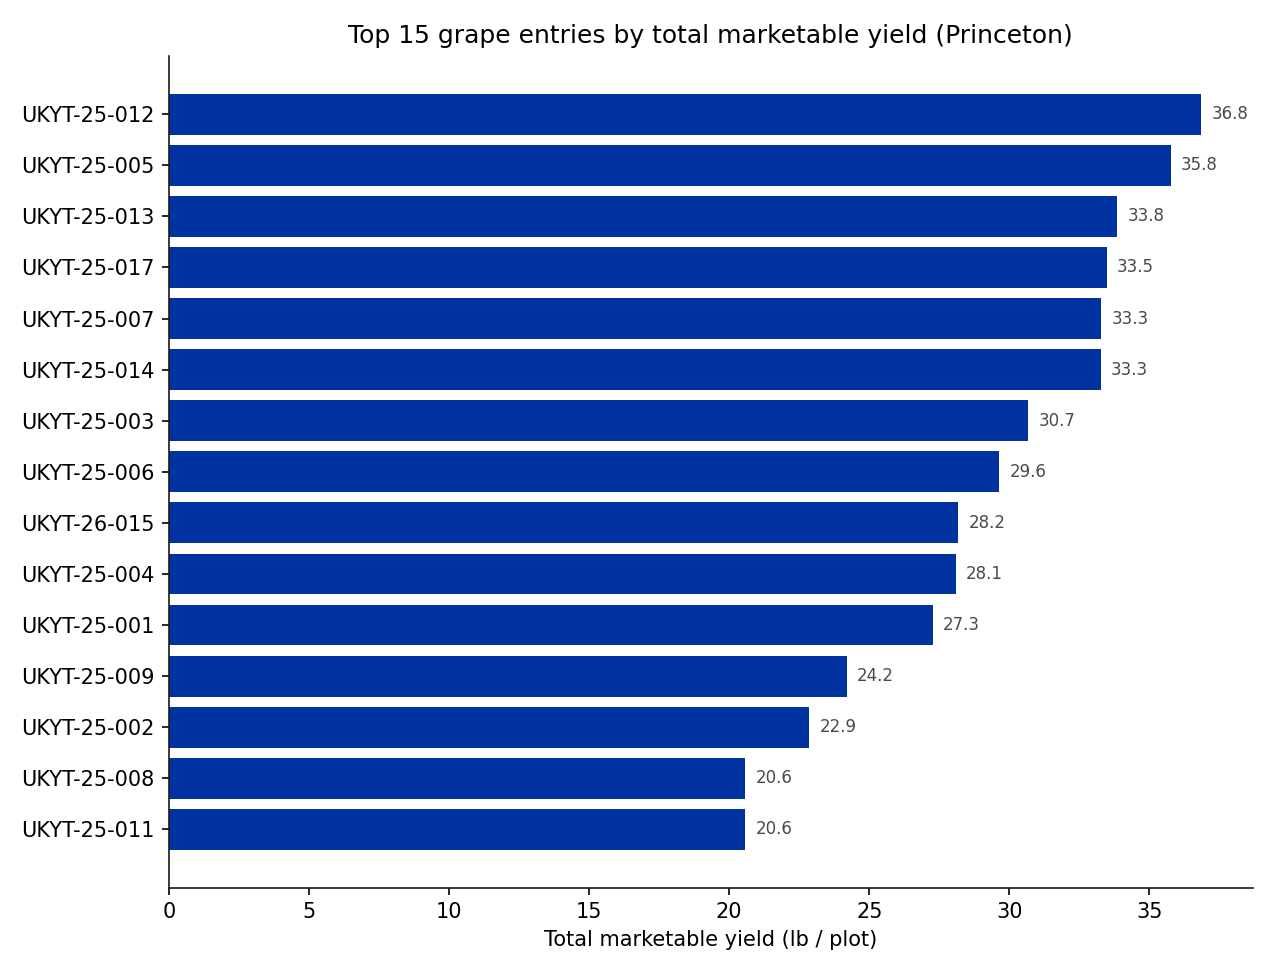

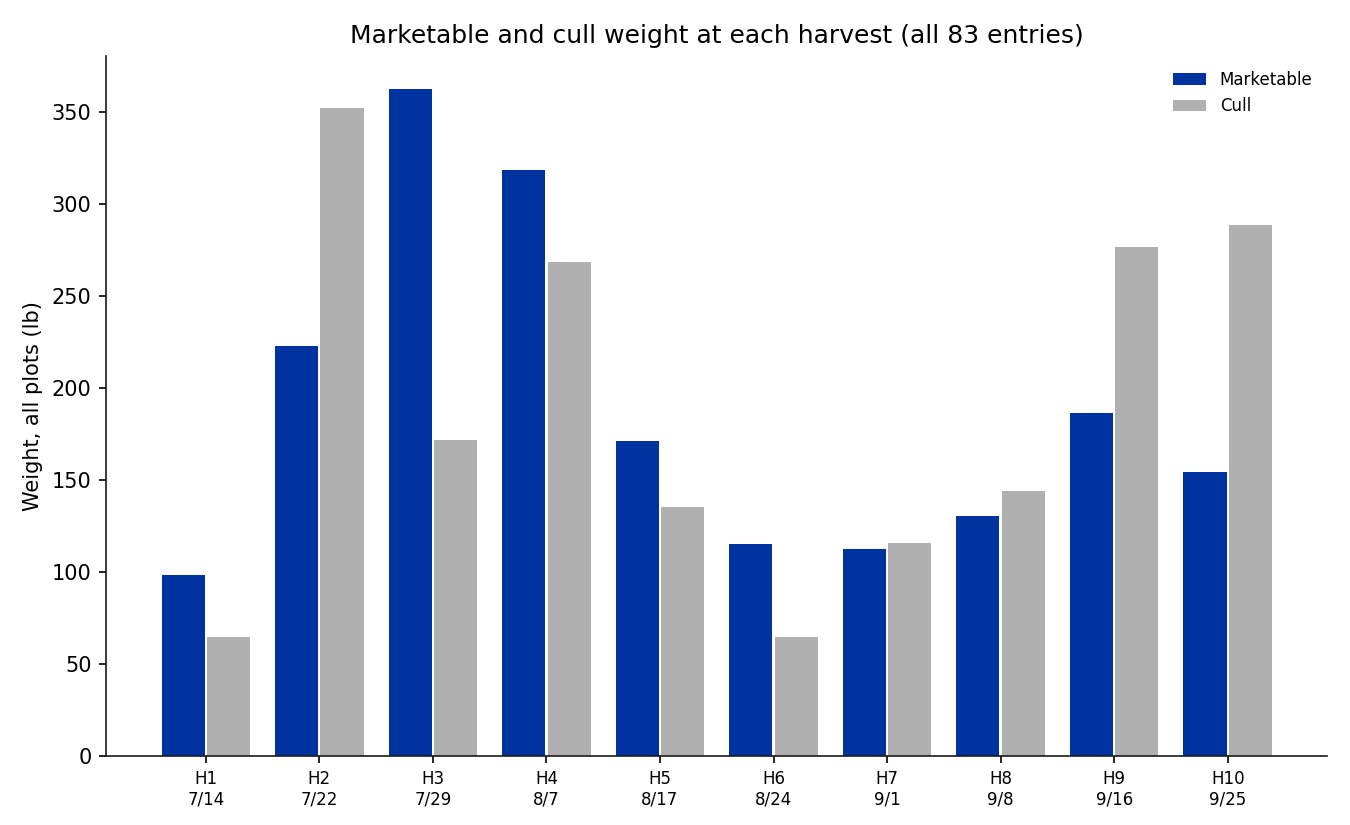

In [12]:
display(Image(filename="figures/princeton_fig1_grape_top15_marketable.png"))
display(Image(filename="figures/princeton_fig3_weight_by_harvest.png"))